# 01 - Análise Exploratória orientada a negócio

**Problema:** identificar clientes de cartão de crédito com alta probabilidade de churn
e traduzir isso em **ação de retenção** (quem, por quê, quanto vale, o que fazer).

**Dados:** BankChurners (Kaggle) — 10.127 clientes, churn ~16%, rotulado em `Attrition_Flag`.
As duas colunas `Naive_Bayes_*` (leak de target) são descartadas na etapa de features.

Perguntas desta etapa:
1. Qual o perfil de quem cancela vs. quem fica?
2. Quais sinais comportamentais se destacam (uso do limite, transações, inatividade, contatos)?
3. Como essas diferenças se relacionam entre si (correlação)?


In [1]:
%matplotlib inline
import sys, pathlib, os
ROOT = pathlib.Path(os.getcwd())
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

import features as fe
import business as bz
import train as T

RAW = ROOT / "data" / "raw" / "BankChurners.csv"
ART = ROOT / "artifacts"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


In [2]:
# Carregamento e limpeza básica (conferir o shape, o alvo e os dados faltantes)
df = pd.read_csv(RAW, encoding="utf-8")
df[fe.TARGET_COLUMN] = df[fe.TARGET_COLUMN].astype(str).str.strip()
for c in ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]:
    df[c] = df[c].astype(str).str.strip()

print("Shape:", df.shape)
print("\nColunas:", list(df.columns))
df.head(3)


Shape: (10127, 23)

Colunas: ['CLIENTNUM', 'Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998


In [3]:
# Taxa de churn geral
df["is_churn"] = (df[fe.TARGET_COLUMN] == fe.TARGET_POSITIVE).astype(int)
churn_rate = df["is_churn"].mean()
print(f"Churn: {churn_rate:.2%}  ({df['is_churn'].sum():,} de {len(df):,} clientes)")

# Dados faltantes
miss = df.isna().mean()[df.isna().mean() > 0]
print("\nFaltantes:", miss.to_dict() if len(miss) else "nenhum")

# Dummies dos racial=não; apenas descritivo
df["Education_Level"].replace("Unknown", pd.NA, inplace=True)
df["Education_Level"].value_counts(dropna=False)


Churn: 16.07%  (1,627 de 10,127 clientes)

Faltantes: nenhum


C:\Users\arthu\AppData\Local\Temp\ipykernel_29088\2355221677.py:11: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["Education_Level"].replace("Unknown", pd.NA, inplace=True)


Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

In [4]:
# Sinais comportamentais: média por grupo (churn vs. ficou)
comp_cols = [
    "Avg_Utilization_Ratio", "Total_Trans_Amt", "Total_Trans_Ct",
    "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Credit_Limit",
    "Total_Revolving_Bal", "Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1",
    "Months_on_book", "Total_Relationship_Count",
]
g = df.groupby("is_churn")[comp_cols].mean().T
g.columns = ["ficou", "saiu"]
g["delta_%"] = ((g["saiu"] - g["ficou"]) / g["ficou"].abs() * 100).round(1)
g.round(2)


,ficou,saiu,delta_%
Avg_Utilization_Ratio,0.30,0.16,-45.2
Total_Trans_Amt,4654.66,3095.03,-33.5
Total_Trans_Ct,68.67,44.93,-34.6
Months_Inactive_12_mon,2.27,2.69,18.5
Contacts_Count_12_mon,2.36,2.97,26.1
Credit_Limit,8726.88,8136.04,-6.8
Total_Revolving_Bal,1256.60,672.82,-46.5
Total_Amt_Chng_Q4_Q1,0.77,0.69,-10.1
Total_Ct_Chng_Q4_Q1,0.74,0.55,-25.3
Months_on_book,35.88,36.18,0.8


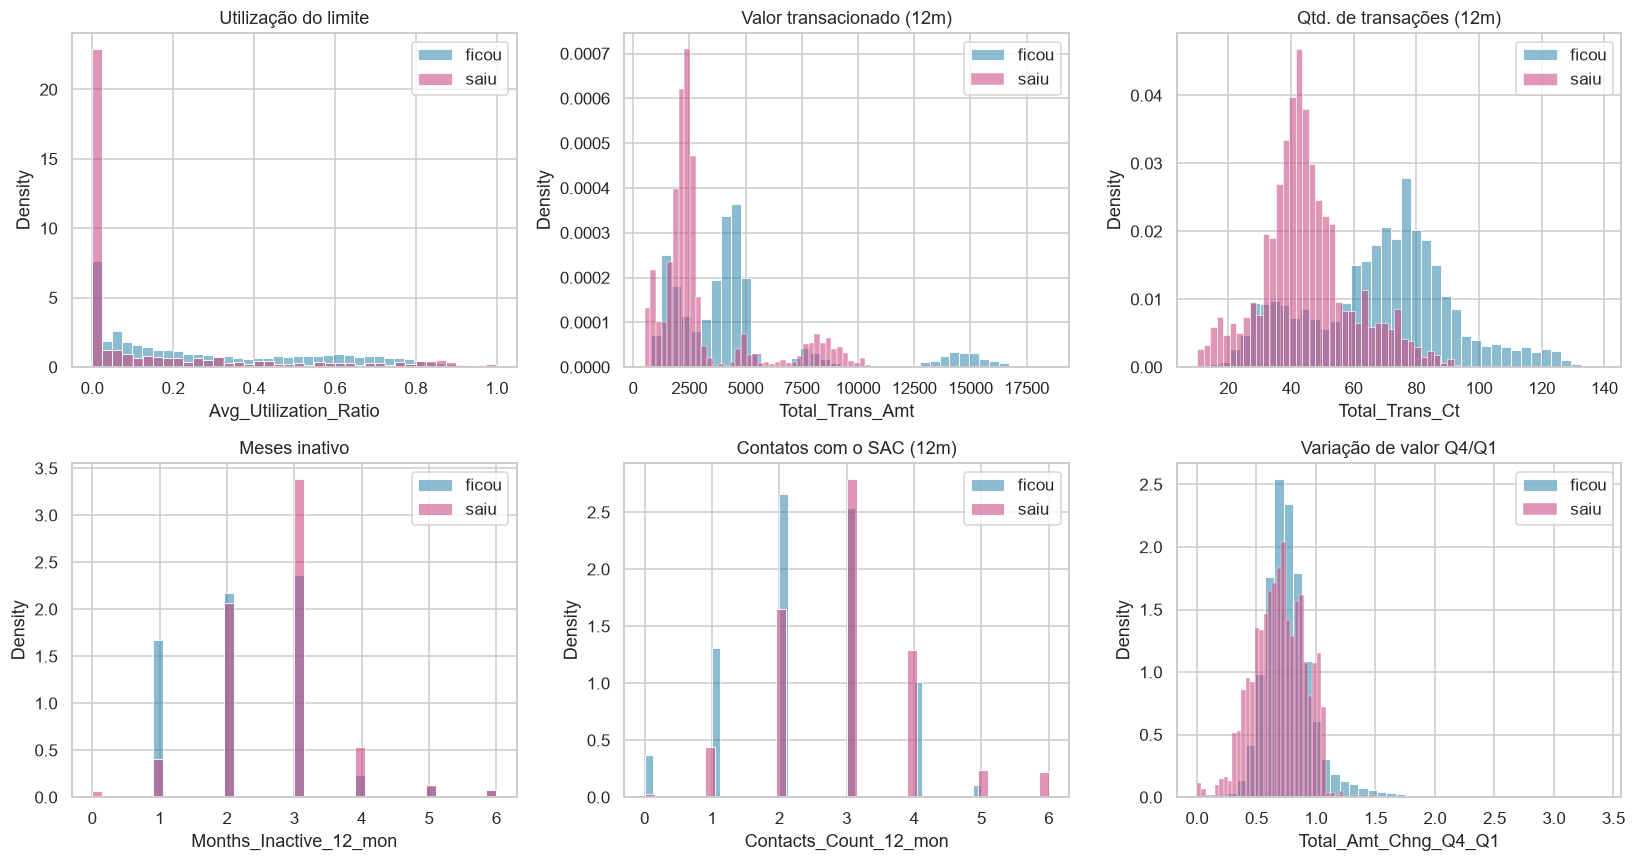

In [5]:
# Distribuição dos principais sinais por desfecho
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
num_list = [
    ("Avg_Utilization_Ratio", "Utilização do limite"),
    ("Total_Trans_Amt", "Valor transacionado (12m)"),
    ("Total_Trans_Ct", "Qtd. de transações (12m)"),
    ("Months_Inactive_12_mon", "Meses inativo"),
    ("Contacts_Count_12_mon", "Contatos com o SAC (12m)"),
    ("Total_Amt_Chng_Q4_Q1", "Variação de valor Q4/Q1"),
]
for ax, (col, label) in zip(axes.ravel(), num_list):
    for churn, cor in [(0, "#2e86ab"), (1, "#c7417b")]:
        sub = df[df["is_churn"] == churn]
        sns.histplot(sub[col], ax=ax, color=cor, label="saiu" if churn else "ficou",
                     stat="density", alpha=0.55, bins=40)
    ax.set_title(label)
    ax.legend()
plt.tight_layout()
plt.savefig(FIG / "eda_sinais.png", bbox_inches="tight")
plt.show()


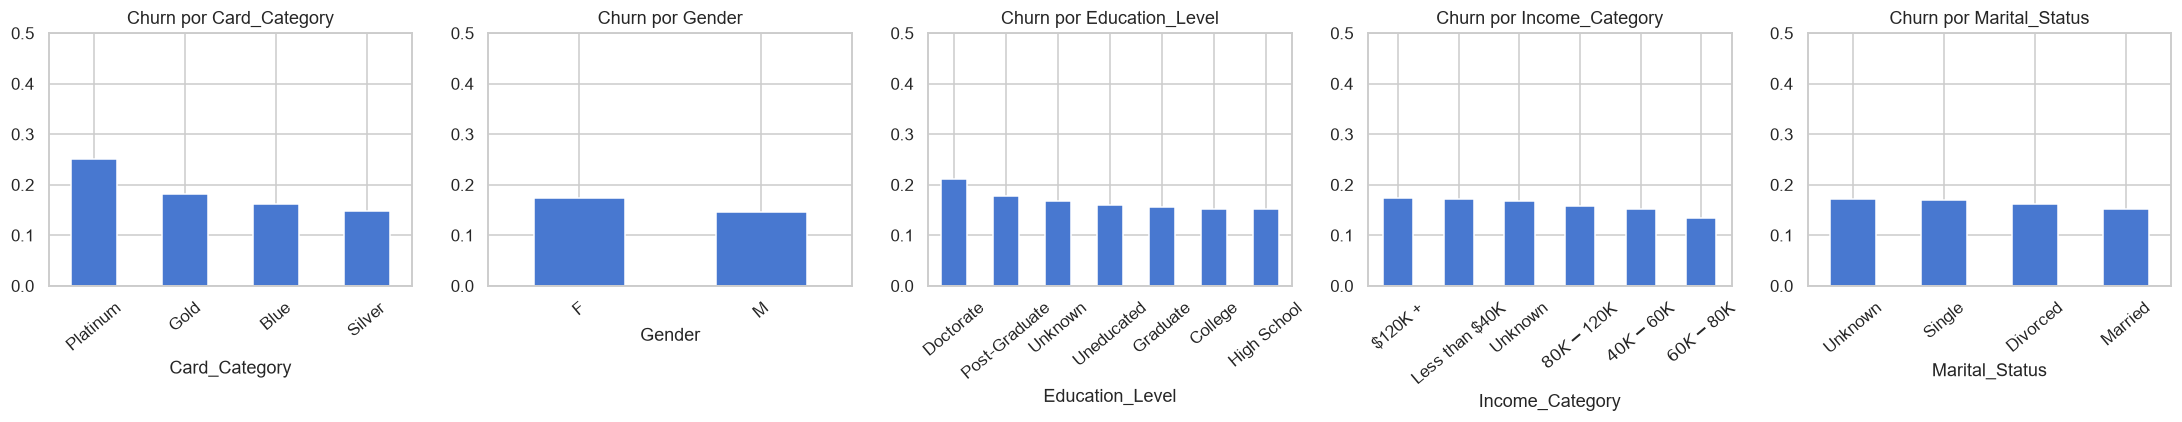

In [6]:
# Churn por categoria (perfil demográfico / produto)
cat_list = ["Card_Category", "Gender", "Education_Level", "Income_Category", "Marital_Status"]
fig, axes = plt.subplots(1, len(cat_list), figsize=(20, 4))
for ax, col in zip(axes, cat_list):
    rates = df.groupby(col, observed=True)["is_churn"].mean().sort_values(ascending=False)
    rates.plot.bar(ax=ax)
    ax.set_title(f"Churn por {col}")
    ax.set_ylim(0, 0.5)
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.savefig(FIG / "eda_churn_categorias.png", bbox_inches="tight")
plt.show()


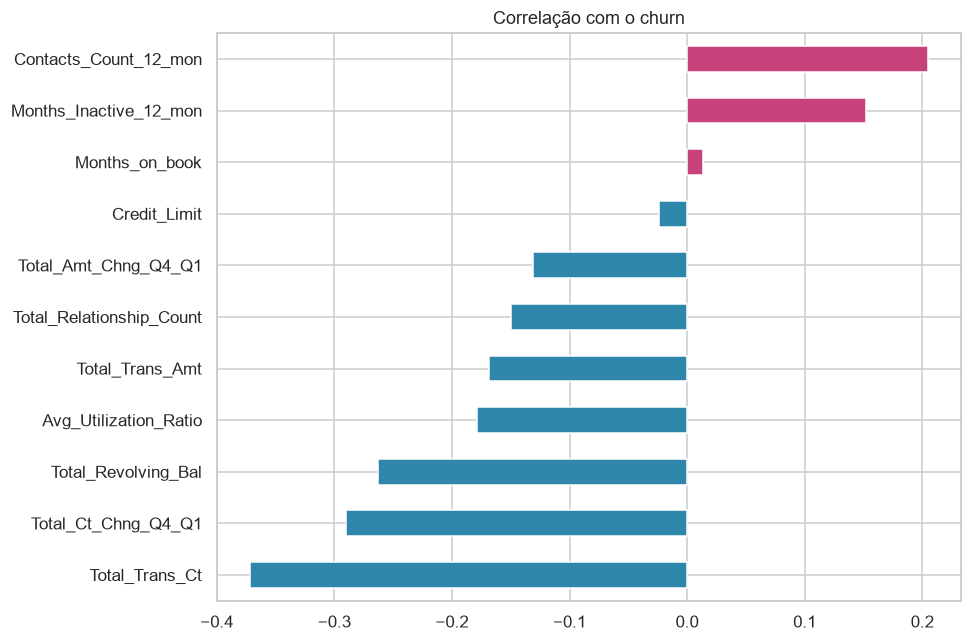

In [7]:
# Correlação com o alvo (top 15)
corr = df[comp_cols + ["is_churn"]].corr()["is_churn"].drop("is_churn").sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
corr.plot.barh(ax=ax, color=["#c7417b" if v > 0 else "#2e86ab" for v in corr])
ax.set_title("Correlação com o churn")
plt.tight_layout()
plt.savefig(FIG / "eda_correlacao.png", bbox_inches="tight")
plt.show()


### Leituras de negócio da EDA

- **Quem está mais propenso a sair:** clientes com **menos transações e menor valor transacionado**,
  **alta utilização do limite** sem crescimento, **meses de inatividade** e **vários contatos com o SAC**
  (insatisfação ou problema operacional).
- **Perfil:** Gold/Platinum têm churn menor (receita por anuidade + uso); clientes de baixa renda e
  sem dependentes aparecem mais no grupo que sai.
- **Sinais antecedentes:** a combinação "inatividade × contatos × queda no Q4 vs. Q1" é o que mais
  distingue os grupos — será transformada em features na próxima etapa.
